# Course End Project: Data Analysis Module Exploratory Data Analysis

Tasks:

1.   Data Loading and Initial Exploration
2.   Data Cleaning
3.   Exploratory Data Analysis
4.   Feature Engineering
5.   Hypothesis Testing (Optional)
6.   Conclusion











# 1. Data Loading and Initial Exploration:
###   Load the selected dataset




### Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Import dataset

In [ ]:
Listings = pd.read_csv("/content/drive/MyDrive/T5/week 3/Project week 3/Listings.csv", encoding='latin1')
Reviews = pd.read_csv("/content/drive/MyDrive/T5/week 3/Project week 3/Reviews.csv", encoding='latin1')

<ipython-input-2-ae0a2267dcf8>:1: DtypeWarning: Columns (5,13) have mixed types. Specify dtype option on import or set low_memory=False.
  Listings = pd.read_csv("/content/drive/MyDrive/T5/week 3/Project week 3/Listings.csv", encoding='latin1')


In [ ]:
Listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279712 entries, 0 to 279711
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   listing_id                   279712 non-null  int64  
 1   name                         279539 non-null  object 
 2   host_id                      279712 non-null  int64  
 3   host_since                   279547 non-null  object 
 4   host_location                278872 non-null  object 
 5   host_response_time           150930 non-null  object 
 6   host_response_rate           150930 non-null  float64
 7   host_acceptance_rate         166625 non-null  float64
 8   host_is_superhost            279547 non-null  object 
 9   host_total_listings_count    279547 non-null  float64
 10  host_has_profile_pic         279547 non-null  object 
 11  host_identity_verified       279547 non-null  object 
 12  neighbourhood                279712 non-null  object 
 13 

In [ ]:
Reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5373143 entries, 0 to 5373142
Data columns (total 4 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   listing_id   int64 
 1   review_id    int64 
 2   date         object
 3   reviewer_id  int64 
dtypes: int64(3), object(1)
memory usage: 164.0+ MB


In [ ]:
Airbnb_dataset = pd.merge(Listings, Reviews, on='listing_id') # merge the two datasets into new dataset 'Airbnb_dataset'

In [ ]:
Airbnb_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 5373143 entries, 0 to 5373142
Data columns (total 36 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   listing_id                   int64  
 1   name                         object 
 2   host_id                      int64  
 3   host_since                   object 
 4   host_location                object 
 5   host_response_time           object 
 6   host_response_rate           float64
 7   host_acceptance_rate         float64
 8   host_is_superhost            object 
 9   host_total_listings_count    float64
 10  host_has_profile_pic         object 
 11  host_identity_verified       object 
 12  neighbourhood                object 
 13  district                     object 
 14  city                         object 
 15  latitude                     float64
 16  longitude                    float64
 17  property_type                object 
 18  room_type                    object 
 19  

### Explore the structure of the dataset (number of rows and columns, data types, etc.)

In [ ]:
Airbnb_dataset.shape

(5373143, 36)

In [ ]:
print(f'The data contains {len(Airbnb_dataset)} rows and {len(Airbnb_dataset.columns)} columns')

The data contains 5373143 rows and 36 columns


In [ ]:
Airbnb_dataset.dtypes

listing_id                       int64
name                            object
host_id                          int64
host_since                      object
host_location                   object
host_response_time              object
host_response_rate             float64
host_acceptance_rate           float64
host_is_superhost               object
host_total_listings_count      float64
host_has_profile_pic            object
host_identity_verified          object
neighbourhood                   object
district                        object
city                            object
latitude                       float64
longitude                      float64
property_type                   object
room_type                       object
accommodates                     int64
bedrooms                       float64
amenities                       object
price                            int64
minimum_nights                   int64
maximum_nights                   int64
review_scores_rating     

### Examine the first few rows of the dataset to understand its contents.

In [ ]:
Airbnb_dataset.head(3)

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,review_id,date,reviewer_id
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,10.0,10.0,10.0,10.0,10.0,10.0,f,173279221,2017-07-23,3501898
1,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,10.0,10.0,10.0,10.0,10.0,10.0,f,172657766,2017-07-21,74346703
2,3705183,39 mÃÂ² Paris (Sacre CÃ âur),10328771,2013-11-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,10.0,10.0,10.0,10.0,10.0,10.0,f,20792760,2014-10-05,21583508


# 2. Data Cleaning:

### Handle missing values appropriately (e.g., imputation, deletion, etc.).



In [ ]:
Airbnb_dataset.isnull()


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,review_id,date,reviewer_id
0,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5373138,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
5373139,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
5373140,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
5373141,False,False,False,False,False,True,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Listings 279712
# Reviews 5373143
# Airbnb_dataset 5373143
Airbnb_dataset.isnull().sum()

listing_id                           0
name                               333
host_id                              0
host_since                        3939
host_location                     7910
host_response_time             1475633
host_response_rate             1475633
host_acceptance_rate            748437
host_is_superhost                 3939
host_total_listings_count         3939
host_has_profile_pic              3939
host_identity_verified            3939
neighbourhood                        0
district                       4525416
city                                 0
latitude                             0
longitude                            0
property_type                        0
room_type                            0
accommodates                         0
bedrooms                        541413
amenities                            0
price                                0
minimum_nights                       0
maximum_nights                       0
review_scores_rating     

In [ ]:
# function to find and display NAs
def count_NAs (dfna,perc):
  NaList = []
  numOfRows = len(dfna)
  for i in dfna.columns:
    numOfNAs = dfna[i].isna().sum()
    print(f'{i:<30}, Row: {numOfRows: >5} , NAs: {numOfNAs: <25}, precentage: {round(numOfNAs/numOfRows * 100.00,2)}')
    if ((numOfNAs/numOfRows) * 100.000) >= perc:
         NaList.append(i)
  print(f'columns with NAs over {perc}%: {NaList}')
  return NaList
cutoff = 40
NAs = count_NAs(Airbnb_dataset, cutoff)
print(f"Total with NAs over {cutoff}% column number :",len(NAs))
# The column that contains more than 40% missing data is the column district

listing_id                    , Row: 5373143 , NAs: 0                        , precentage: 0.0
name                          , Row: 5373143 , NAs: 333                      , precentage: 0.01
host_id                       , Row: 5373143 , NAs: 0                        , precentage: 0.0
host_since                    , Row: 5373143 , NAs: 3939                     , precentage: 0.07
host_location                 , Row: 5373143 , NAs: 7910                     , precentage: 0.15
host_response_time            , Row: 5373143 , NAs: 1475633                  , precentage: 27.46
host_response_rate            , Row: 5373143 , NAs: 1475633                  , precentage: 27.46
host_acceptance_rate          , Row: 5373143 , NAs: 748437                   , precentage: 13.93
host_is_superhost             , Row: 5373143 , NAs: 3939                     , precentage: 0.07
host_total_listings_count     , Row: 5373143 , NAs: 3939                     , precentage: 0.07
host_has_profile_pic          , Row: 53

In [ ]:
Airbnb_dataset.drop(NAs, axis = 1, inplace = True) # removing columns with NAs columns over 40%

In [ ]:
Airbnb_dataset.columns

Index(['listing_id', 'name', 'host_id', 'host_since', 'host_location',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_total_listings_count',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'city', 'latitude', 'longitude', 'property_type', 'room_type',
       'accommodates', 'bedrooms', 'amenities', 'price', 'minimum_nights',
       'maximum_nights', 'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'instant_bookable', 'review_id', 'date',
       'reviewer_id'],
      dtype='object')

### explore the data in each column that contains missing data

In [ ]:
Airbnb_dataset['bedrooms']

0          1.0
1          1.0
2          1.0
3          1.0
4          1.0
          ... 
5373138    1.0
5373139    1.0
5373140    1.0
5373141    1.0
5373142    1.0
Name: bedrooms, Length: 5373143, dtype: float64

In [ ]:
Airbnb_dataset['host_since'].value_counts().max()

11629

In [ ]:
Airbnb_dataset['host_response_time'].value_counts().max()

2665754

In [ ]:
Airbnb_dataset['host_response_rate'].value_counts().max()

2944035

In [ ]:
Airbnb_dataset['host_acceptance_rate'].value_counts().max()

2338154

In [ ]:
Airbnb_dataset['host_is_superhost'].value_counts().max()

3009692

### Dealing with null values
- name  ✅
- host_since ✅
- host_location ✅
- host_response_time ✅
- host_response_rate ✅
- host_acceptance_rate ✅
- host_is_superhost ✅
- host_total_listings_count ✅
- host_has_profile_pic ✅
- host_identity_verified ✅
- bedrooms ✅
- review_scores_rating ✅
- review_scores_accuracy  ✅
- review_scores_cleanliness  ✅
- review_scores_checkin ✅
- review_scores_communication ✅
- review_scores_location ✅
- review_scores_value ✅

In [ ]:
def Null_Values(Airbnb_dataset):
  Airbnb_dataset['name'].fillna('Unknown', inplace=True) # fills the missing values with 'Unknown'
  Airbnb_dataset['host_since'].fillna(pd.to_datetime('2019-09-02'), inplace=True) # fill null values with a default date value 2019-09-02 (most frequent value in host since)
  Airbnb_dataset['host_location'].fillna(Airbnb_dataset['host_location'].mode()[0], inplace=True) # fills the missing values with the most frequent value
  Airbnb_dataset['host_response_time'].fillna('within an hour' ,inplace=True) # fill null values with a default time value
  Airbnb_dataset['host_response_rate'] = Airbnb_dataset['host_response_rate']
  Airbnb_dataset['host_response_rate'].fillna((Airbnb_dataset[['host_response_rate']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['host_acceptance_rate'].fillna((Airbnb_dataset[['host_acceptance_rate']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['host_is_superhost'].fillna('Unknown', inplace=True) # fills the missing values with 'Unknown'
  Airbnb_dataset['host_total_listings_count'].fillna(Airbnb_dataset['host_total_listings_count'].mean().item(), inplace=True)# fills the missing values with mean
  Airbnb_dataset['host_has_profile_pic'].fillna(Airbnb_dataset['host_has_profile_pic'].mode()[0], inplace=True) # fills the missing values with the most frequent value
  Airbnb_dataset['host_identity_verified'].fillna(Airbnb_dataset['host_identity_verified'].mode()[0], inplace=True) # fills the missing values with the most frequent value
  Airbnb_dataset['bedrooms'].fillna((Airbnb_dataset[['bedrooms']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_rating'].fillna((Airbnb_dataset[['review_scores_rating']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_accuracy'].fillna((Airbnb_dataset[['review_scores_accuracy']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_cleanliness'].fillna((Airbnb_dataset[['review_scores_cleanliness']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_checkin'].fillna((Airbnb_dataset[['review_scores_checkin']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_communication'].fillna((Airbnb_dataset[['review_scores_communication']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_location'].fillna((Airbnb_dataset[['review_scores_location']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
  Airbnb_dataset['review_scores_value'].fillna((Airbnb_dataset[['review_scores_value']].astype(float)).median()[0], inplace=True) # fills the missing values with Median
Null_Values(Airbnb_dataset)
Airbnb_dataset.isnull().sum()

listing_id                     0
name                           0
host_id                        0
host_since                     0
host_location                  0
host_response_time             0
host_response_rate             0
host_acceptance_rate           0
host_is_superhost              0
host_total_listings_count      0
host_has_profile_pic           0
host_identity_verified         0
neighbourhood                  0
city                           0
latitude                       0
longitude                      0
property_type                  0
room_type                      0
accommodates                   0
bedrooms                       0
amenities                      0
price                          0
minimum_nights                 0
maximum_nights                 0
review_scores_rating           0
review_scores_accuracy         0
review_scores_cleanliness      0
review_scores_checkin          0
review_scores_communication    0
review_scores_location         0
review_sco

### Check for and handle any duplicate entries.

In [ ]:
Airbnb_dataset.duplicated().sum() # There is no duplicate

0

### Convert categorical variables into the appropriate data type if necessary.

In [ ]:
Airbnb_dataset.dtypes

listing_id                       int64
name                            object
host_id                          int64
host_since                      object
host_location                   object
host_response_time              object
host_response_rate             float64
host_acceptance_rate           float64
host_is_superhost               object
host_total_listings_count      float64
host_has_profile_pic            object
host_identity_verified          object
neighbourhood                   object
city                            object
latitude                       float64
longitude                      float64
property_type                   object
room_type                       object
accommodates                     int64
bedrooms                       float64
amenities                       object
price                            int64
minimum_nights                   int64
maximum_nights                   int64
review_scores_rating           float64
review_scores_accuracy   

In [ ]:
Airbnb_dataset['host_since'] = pd.to_datetime(Airbnb_dataset['host_since']) # convert host_since type from object to datetime

In [ ]:
# convert categorical variables into the appropriate data type
category_columns = ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable']
Airbnb_dataset[category_columns] = Airbnb_dataset[category_columns].astype('category')

In [ ]:
Airbnb_dataset.dtypes

listing_id                              int64
name                                   object
host_id                                 int64
host_since                     datetime64[ns]
host_location                          object
host_response_time                     object
host_response_rate                    float64
host_acceptance_rate                  float64
host_is_superhost                    category
host_total_listings_count             float64
host_has_profile_pic                 category
host_identity_verified               category
neighbourhood                          object
city                                   object
latitude                              float64
longitude                             float64
property_type                          object
room_type                              object
accommodates                            int64
bedrooms                              float64
amenities                              object
price                             

In [ ]:
Airbnb_dataset['date'] = pd.to_datetime(Airbnb_dataset['date']) # Convert date type from object to datetime

# 3. Exploratory Data Analysis:

### Conduct univariate analysis to understand the distribution of individual variables (e.g., listing prices, number of reviews, etc.).

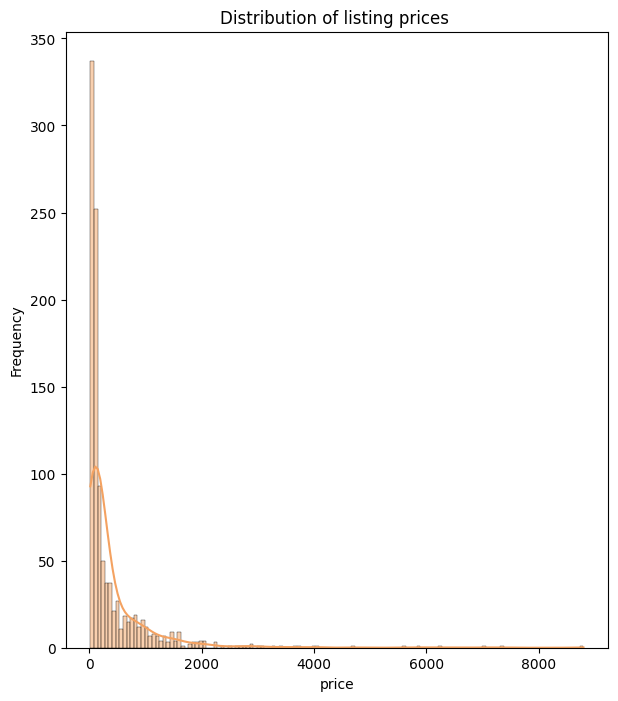

In [ ]:
# Distribution of listing prices
sample_price = Airbnb_dataset.sample(frac=0.0002)
plt.figure(figsize=(7,8))
sns.histplot(sample_price['price'], kde=True,color='#F4A261')
plt.xlabel('price')
plt.ylabel('Frequency')
plt.title('Distribution of listing prices ')
plt.show()

In [ ]:
print('The max price:',Airbnb_dataset['price'].max())
print('The min price:', Airbnb_dataset['price'].min())

The max price: 300177
The min price: 8


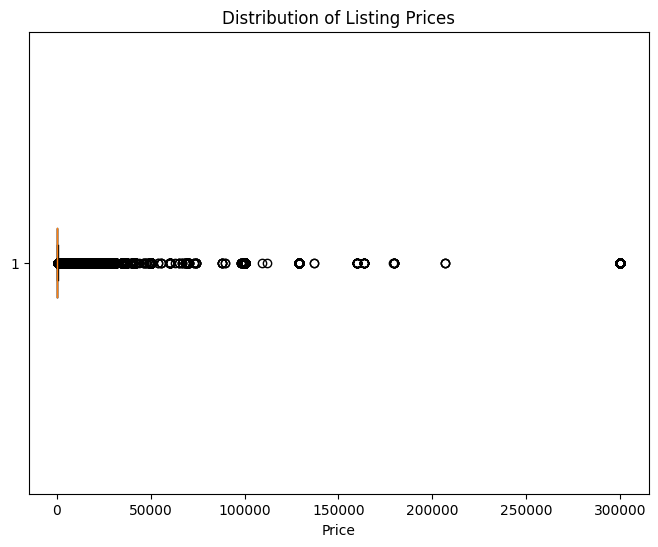

In [ ]:
# Create a box plot for the distribution of listing prices
plt.figure(figsize=(8, 6))
plt.boxplot(Airbnb_dataset['price'], vert=False)
plt.xlabel('Price')
plt.title('Distribution of Listing Prices')
plt.show()
# there is outlier

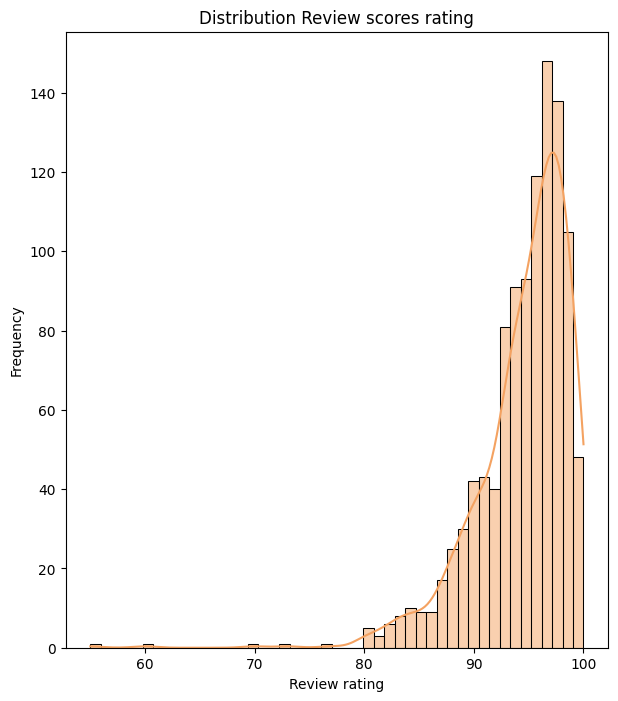

In [ ]:
# Distribution of Number of Reviews
sample_Num_reviews = Airbnb_dataset.sample(frac=0.0005)
plt.figure(figsize=(7,8))
sns.histplot(sample_price['review_scores_rating'], kde=True,color='#F4A261')
plt.xlabel('Review rating')
plt.ylabel('Frequency')
plt.title('Distribution Review scores rating')
plt.show()

### Perform bivariate analysis to explore relationships between variables (e.g., price vs. property type, price vs. neighborhood, etc.).

Text(0.5, 0, 'Host property type')

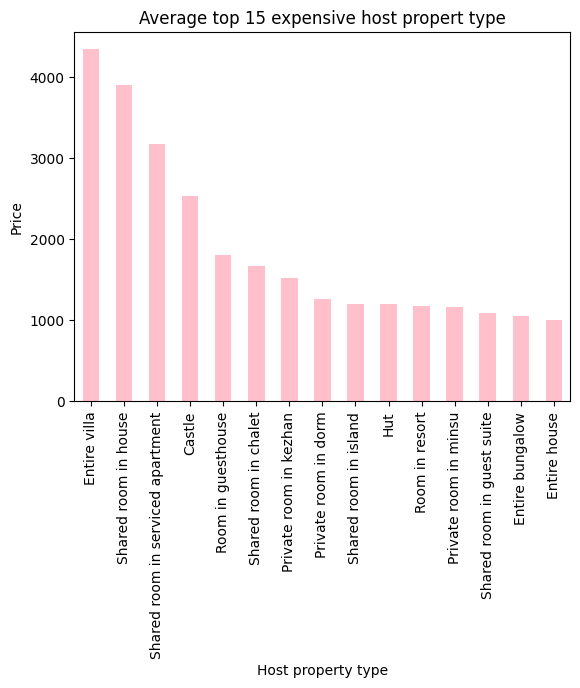

In [ ]:
Airbnb_dataset.groupby(['property_type'])['price'].mean().sort_values(ascending=False)[:15].plot.bar(color='pink') # Calculate the average price per property_type
plt.title('Average top 15 expensive host propert type')
plt.ylabel('Price')
plt.xlabel('Host property type')

Text(0.5, 0, 'Host neighbourhood')

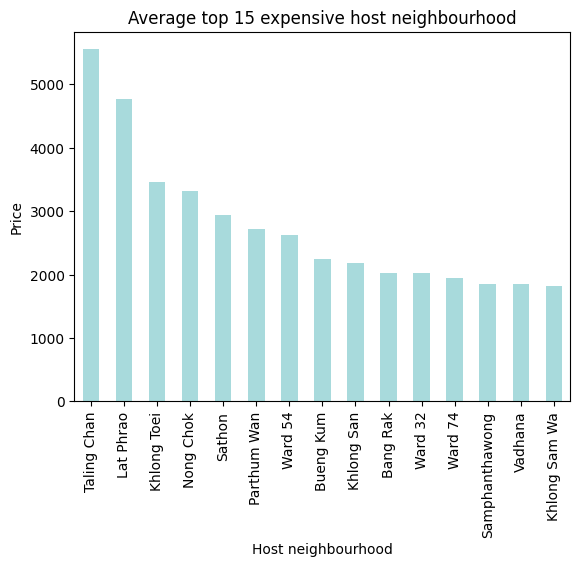

In [ ]:
Airbnb_dataset.groupby(['neighbourhood'])['price'].mean().sort_values(ascending=False)[:15].plot.bar(color='#A8DADC') # Calculate the average price per neighbourhood
plt.title('Average top 15 expensive host neighbourhood')
plt.ylabel('Price')
plt.xlabel('Host neighbourhood')

In [ ]:
import plotly.express as px
# Group by room_type and calculate max price, then select top 10
top10_ = Airbnb_dataset.groupby('room_type')['price'].max().sort_values(ascending=False)[:10]
top_data = top10_.reset_index()
colors = ['#457B9D',  '#A8DADC', '#F4A261','#2A9D8F',  '#1D3557', '#F1FAEE', '#2A9D8F', '#264653']
fig = px.pie(top_data, values='price', names='room_type', title='Top 10 room_type by average Price', color_discrete_sequence=colors)
fig.show()


In [ ]:
review_scores_cleanliness = Airbnb_dataset.groupby("city")["review_scores_cleanliness"].mean().sort_values(ascending=False) * 100
review_scores_cleanliness

city
Cape Town         972.164082
Mexico City       968.654729
Rome              958.858321
Rio de Janeiro    954.852849
Bangkok           953.915707
Sydney            953.174995
New York          946.604862
Paris             934.211647
Istanbul          932.587507
Hong Kong         925.581846
Name: review_scores_cleanliness, dtype: float64

In [ ]:
# Calculate the average price for accomodations in each city
avg_price_city = Airbnb_dataset.groupby('city')['price'].mean().sort_values()
avg_price_city

city
Rome                81.285026
Paris              108.533496
New York           122.163961
Sydney             197.979847
Rio de Janeiro     356.698281
Istanbul           373.125646
Hong Kong          660.476681
Mexico City        968.679472
Cape Town         1428.313671
Bangkok           1880.728594
Name: price, dtype: float64

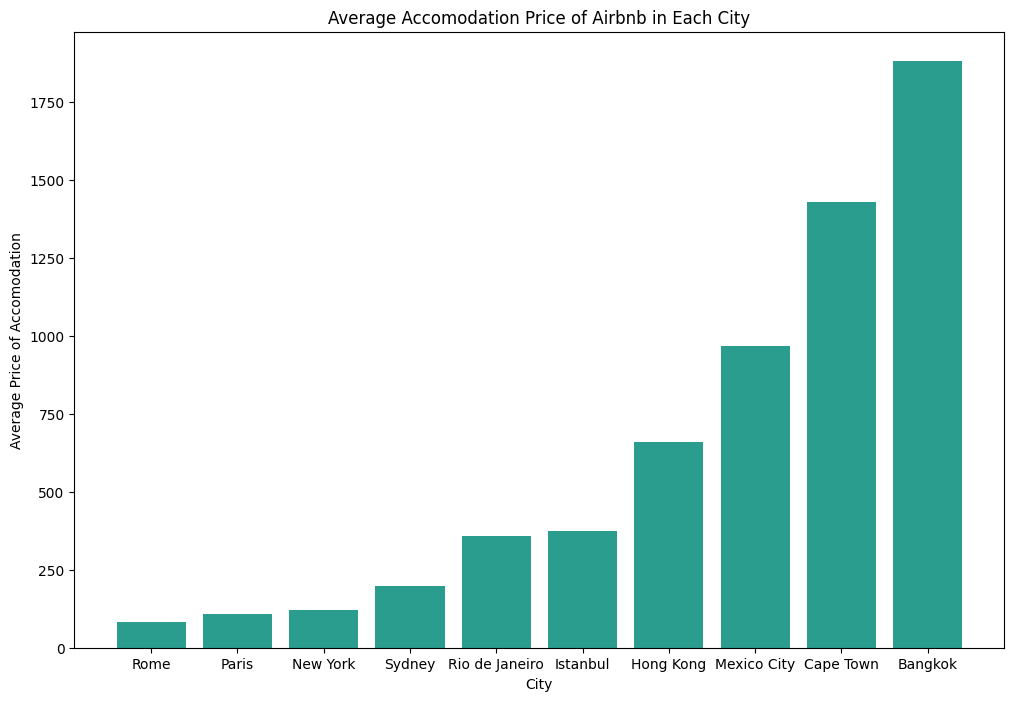

In [ ]:
# Display the graph for value for travel in each city
plt.figure(figsize = (12,8))
plt.bar(avg_price_city.index, avg_price_city.values, color = '#2A9D8F')
plt.title('Average Accomodation Price of Airbnb in Each City')
plt.ylabel('Average Price of Accomodation')
plt.xlabel('City')
plt.show()

In [ ]:
# Grouping instant_bookable with city
Airbnb_dataset.groupby('city')['instant_bookable'].count().sort_values(ascending = False)

city
Paris             1213727
Rome              1113360
New York           847727
Sydney             482552
Mexico City        477584
Rio de Janeiro     323274
Cape Town          302336
Bangkok            284342
Istanbul           194013
Hong Kong          134228
Name: instant_bookable, dtype: int64

Text(0.5, 0, 'city')

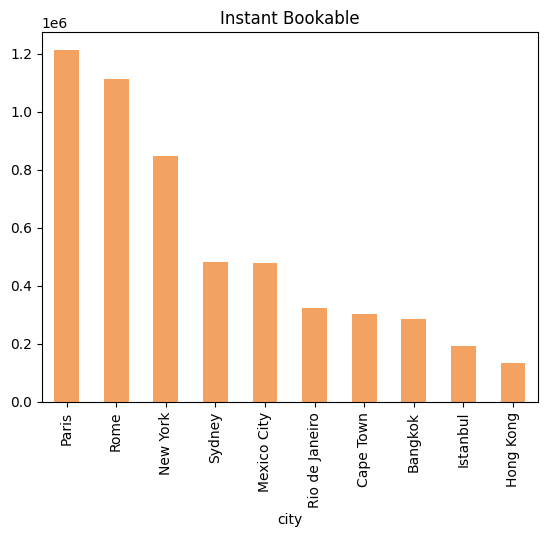

In [ ]:
# Display the graph for value for instant_bookable in each city
Airbnb_dataset.groupby(['city'])['instant_bookable'].count().sort_values(ascending=False)[:10].plot.bar(color='#F4A261')
plt.title('Instant Bookable')
plt.xlabel('city')

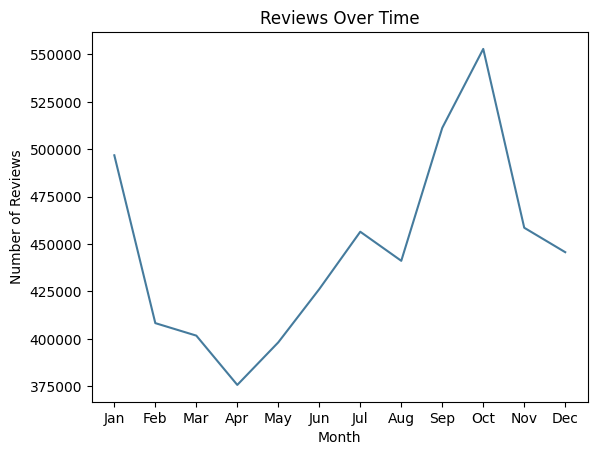

In [ ]:
reviews_over_time = Airbnb_dataset.groupby(Airbnb_dataset['date'].dt.month)['reviewer_id'].count()
plt.plot(range(1, 13), reviews_over_time, label='Reviews per Month',color='#457B9D')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.title('Reviews Over Time')
plt.show()

In [ ]:
Airbnb_dataset['number_amenities'] = Airbnb_dataset['amenities'].apply(lambda x: len(x)).sort_values(ascending = False)
print(Airbnb_dataset[['city', 'number_amenities']])
# Paris contains more amenities than other cities

          city  number_amenities
0        Paris                67
1        Paris                67
2        Paris               101
3        Paris               101
4        Paris               101
...        ...               ...
5373138  Paris               228
5373139  Paris               228
5373140  Paris               190
5373141  Paris               256
5373142  Paris               256

[5373143 rows x 2 columns]


In [ ]:
# Display the total number of bedrooms in each city
bedrooms_per_city = Airbnb_dataset.groupby('city')['bedrooms'].sum().reset_index(name='total_bedrooms')
print(bedrooms_per_city)
# Parise have more bedrooms than rome

             city  total_bedrooms
0         Bangkok        392214.0
1       Cape Town        502444.0
2       Hong Kong        171097.0
3        Istanbul        280907.0
4     Mexico City        710227.0
5        New York       1094900.0
6           Paris       1595958.0
7  Rio de Janeiro        481312.0
8            Rome       1607492.0
9          Sydney        712687.0


In [ ]:
# Group the dataset by 'host_since' and count the number of unique hosts within each group
hosts_per_date = Airbnb_dataset.groupby('host_since').size().reset_index(name='num_hosts')

# Display the number of hosts for each date they started hosting
print(hosts_per_date)

     host_since  num_hosts
0    2008-08-12         48
1    2008-08-13        123
2    2008-08-20        111
3    2008-08-22          1
4    2008-08-27         33
...         ...        ...
4194 2021-02-11         11
4195 2021-02-13          1
4196 2021-02-17         35
4197 2021-02-18          2
4198 2021-02-20          1

[4199 rows x 2 columns]


In [ ]:
print('The max number of hosts:', hosts_per_date.max())
print('The min number of hosts:', hosts_per_date.min())

The max number of hosts: host_since    2021-02-20 00:00:00
num_hosts                   15568
dtype: object
The min number of hosts: host_since    2008-08-12 00:00:00
num_hosts                       1
dtype: object


In [ ]:
relevant_variables = ['listing_id', 'host_id', 'accommodates', 'bedrooms', 'price',
                      'minimum_nights', 'maximum_nights', 'review_scores_rating', 'review_scores_accuracy',
                      'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication',
                       'review_scores_value', 'review_id', 'reviewer_id']

# Calculate summary statistics
summary_stats = Airbnb_dataset[relevant_variables].describe()
# Display the summary statistics
print(summary_stats)




         listing_id       host_id  accommodates      bedrooms         price  \
count  5.373143e+06  5.373143e+06  5.373143e+06  5.373143e+06  5.373143e+06   
mean   1.602989e+07  6.469994e+07  3.449121e+00  1.404995e+00  3.958410e+02   
std    1.198676e+07  7.826077e+07  2.023092e+00  1.037714e+00  2.423261e+03   
min    2.577000e+03  1.822000e+03  1.000000e+00  1.000000e+00  8.000000e+00   
25%    5.332708e+06  8.803928e+06  2.000000e+00  1.000000e+00  6.600000e+01   
50%    1.450814e+07  3.082557e+07  3.000000e+00  1.000000e+00  1.150000e+02   
75%    2.414496e+07  9.478960e+07  4.000000e+00  2.000000e+00  3.280000e+02   
max    4.826387e+07  3.893169e+08  1.600000e+01  5.000000e+01  3.001770e+05   

       minimum_nights  maximum_nights  review_scores_rating  \
count    5.373143e+06    5.373143e+06          5.373143e+06   
mean     5.926587e+00    1.367270e+05          9.458283e+01   
std      3.336257e+01    1.670686e+07          4.600847e+00   
min      1.000000e+00    1.000000e+0

# 4. Feature Engineering:

### Create new features that might be useful for analysis (e.g., average rating, occupancy rate, etc.).

In [ ]:
 # Extract data features
Airbnb_dataset['average_rating'] = Airbnb_dataset[['review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
                                  'review_scores_communication', 'review_scores_location', 'review_scores_value']].mean(axis=1)

In [ ]:
# Find max and min average_rating
least_avg_rating = Airbnb_dataset['average_rating'].min()
most_avg_rating = Airbnb_dataset['average_rating'].max()
print('The most rating is {} and the least is {}'.format(most_avg_rating, least_avg_rating))

The most rating is 10.0 and the least is 2.0


In [ ]:
# Occupancy Rate calculated as the ratio of the number of nights the property was booked to the total number of available nights.
Airbnb_dataset['occupancy_rate'] = Airbnb_dataset['maximum_nights'] - Airbnb_dataset['minimum_nights'] / Airbnb_dataset['maximum_nights']
Airbnb_dataset['occupancy_rate']

0          1124.998222
1          1124.998222
2          1124.998222
3          1124.998222
4          1124.998222
              ...     
5373138      29.800000
5373139      29.800000
5373140      17.833333
5373141       3.500000
5373142       3.500000
Name: occupancy_rate, Length: 5373143, dtype: float64

In [ ]:
# Calculate total available nights for each listing
Airbnb_dataset['total_nights'] = Airbnb_dataset['maximum_nights'] - Airbnb_dataset['minimum_nights']
# Group the dataset by city and calculate total occupied nights and total available nights
occupancy_stats = Airbnb_dataset.groupby('city').agg(total_occupied_nights=('total_nights', 'sum'),
                                                     total_available_nights=('total_nights', 'count'))
# Calculate occupancy rate for each city
occupancy_stats['occupancy_rate'] = (occupancy_stats['total_occupied_nights'] / occupancy_stats['total_available_nights']).sort_values(ascending = False) * 100
# Display the occupancy rate for each city
print(occupancy_stats)


                total_occupied_nights  total_available_nights  occupancy_rate
city                                                                         
Bangkok                     241643463                  284342    8.498339e+04
Cape Town                   267351481                  302336    8.842860e+04
Hong Kong                   101856721                  134228    7.588336e+04
Istanbul                 275042615846                  194013    1.417650e+08
Mexico City                 347417489                  477584    7.274479e+04
New York                   6970232248                  847727    8.222261e+05
Paris                       782623958                 1213727    6.448105e+04
Rio de Janeiro            61188768749                  323274    1.892783e+07
Rome                     389353912709                 1113360    3.497107e+07
Sydney                      325660890                  482552    6.748721e+04


In [ ]:
# Creating a new columns Months from date
Airbnb_dataset['Months'] = pd.to_datetime(Airbnb_dataset['date'], infer_datetime_format=True).dt.month
Airbnb_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 5373143 entries, 0 to 5373142
Data columns (total 40 columns):
 #   Column                       Dtype         
---  ------                       -----         
 0   listing_id                   int64         
 1   name                         object        
 2   host_id                      int64         
 3   host_since                   datetime64[ns]
 4   host_location                object        
 5   host_response_time           object        
 6   host_response_rate           float64       
 7   host_acceptance_rate         float64       
 8   host_is_superhost            category      
 9   host_total_listings_count    float64       
 10  host_has_profile_pic         category      
 11  host_identity_verified       category      
 12  neighbourhood                object        
 13  city                         object        
 14  latitude                     float64       
 15  longitude                    float64       
 16  

In [ ]:
occupancy_rate_by_month = Airbnb_dataset.groupby('Months')['occupancy_rate'].mean().sort_values(ascending=False)
# Display the occupancy rate by month
print(occupancy_rate_by_month)

Months
5     215992.394460
4     160672.612845
7     152733.838984
6     151085.074260
8     148020.552403
10    145638.442560
3     133987.014327
11    128313.638970
1     121680.861192
9     113488.614351
2      93896.587759
12     87159.140309
Name: occupancy_rate, dtype: float64


### Encode categorical variables

In [ ]:
# convert multiple categorical columns into binary variables using label encoder
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
category_binary_columns = ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable']

for column in category_binary_columns:
    Airbnb_dataset[column] = label_encoder.fit_transform(Airbnb_dataset[column])

In [ ]:
Airbnb_dataset[category_binary_columns].head()

,host_is_superhost,host_has_profile_pic,host_identity_verified,instant_bookable
0,1,1,0,0
1,1,1,0,0
2,1,1,1,0
3,1,1,1,0
4,1,1,1,0


# Conclusion:

### Summarize the findings from the exploratory data analysis.

*   The prices distribution from 0 to 8000.
* The Distribution of Review scores rating from 50 to 100
*   The most expensive host propert type is Entire villa and the least Entire house
* The most expensive host neighbourthood is Taling chan and the least Khlong sam wa
* Top room type by average Price is Private room with 47.1%
* The most review scores cleanliness city is Cape Town , Mexico City and Rome
* Highest average housing price in Airbnb is Bangkok city and least average housing price is Rome
* The highest booking cities are Paris and Rome and the least Hong kong.
* ٌReviews was increased during the months of September and October.
* Paris contains more amenities than other cities
* Bangkok have the most number of bedrooms
* The most occupancy rate is month 5
### Discuss any insights or patterns observed in the data.

Based on the analysis and visualizations, I can conclude several insights and patterns


1.   There is a regular difference in reviews throughout the year, which may indicate seasonal trends in booking activity. Holidays, vacations, and months with a high demand for travel might all influence this.
2.   Prices for entire homes and apartments are often higher compared to prices for private and shared rooms.
3. It seems that pricing trends in various cities, like Paris and Rome, are comparable.
### Make recommendations based on the analysis conducted.
 * Use dynamic pricing to modify prices in response to seasonal fluctuations in the volume of reservations. To draw more visitors and increase occupancy rates.
 * Continue to prioritize entire home/apartment listings, as they tend to command higher prices. To appeal to tourists on a limited budget, think about providing affordable pricing for both private and shared accommodations.

